# <p style="color:pink">Dataset used : 
induced in-vitro transition process, the Epithelial-to-Mesenchymal Transition (EMT) of human A549 cells treated with TGF-β or TNF or EGF for different durations. Single-cell RNA-seq profiles of 12 EMT time course experiments spanning multiple cell lines and EMT inducers, and independent kinase inhibitor screens for each. This notebook uses the A549 (lung carcinoma) cell line data. 
## <p style="color:coral">Reference : 
D. P. Cook and B. C. Vanderhyden, Context specificity of the EMT transcriptional response, Nat. Commun. 11, 2142 (2020). 
GSE147405

### <p style="color:pink">Libraries and dependencies</p>

In [112]:
# Import libraries for gene annotation, data handling, graph analysis, visualization,
# single-cell analysis, and MAGIC-based imputation.
import mygene
import pyreadr
import numpy as np
from scipy.sparse.csgraph import connected_components
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import magic

### <p style="color:pink">Load data -- Please replace the path below to the dataset you want to analyse</p>

In [192]:
# Load the A549 EGF single-cell RNA-seq dataset as an AnnData object.
adata = sc.read('/home/csb/Saloni/SCENT/data/A549_TNF.h5ad')

# Inspect the dimensions and metadata structure of the loaded dataset.
print(adata)

AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime'


In [193]:
print(adata.obs['Time'].value_counts())

Time
1d       1955
3d       1912
7d       1669
8h       1659
1d_rm    1544
3d_rm    1501
8h_rm    1404
0d       1267
Name: count, dtype: int64


### <p style="color:pink">Imputate with magic (Will be used later for our scatter plots)</p>

In [194]:
# ============================================================
# MAKE MAGIC COPY
# ============================================================

# Create a separate copy so that MAGIC preprocessing/imputation does not modify the original AnnData object.
adata_magic = adata.copy()

print("Original:", adata_magic.shape)


# ============================================================
# NORMALIZE + LOG TRANSFORM
# ============================================================

# Normalize each cell to the same total count and log-transform expression
# values to reduce the effect of sequencing depth and highly expressed genes.
sc.pp.normalize_total(
    adata_magic,
    target_sum=1e4
)

sc.pp.log1p(adata_magic)


# ============================================================
# RUN MAGIC
# ============================================================

# Initialize MAGIC, which smooths/imputes gene expression based on
# similarities between cells to reduce sparsity/dropout effects.
magic_operator = magic.MAGIC(
    n_jobs=-1,
    random_state=42
)

adata_magic.X = magic_operator.fit_transform(
    adata_magic.X
)

print("MAGIC completed")
print(adata_magic)

Original: (12911, 13143)
Calculating MAGIC...
  Running MAGIC on 12911 cells and 13143 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 8.50 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.09 seconds.
    Calculating affinities...
    Calculated affinities in 0.22 seconds.
  Calculated graph and diffusion operator in 8.82 seconds.
  Running MAGIC with `solver='exact'` on 13143-dimensional data may take a long time. Consider denoising specific genes with `genes=<list-like>` or using `solver='approximate'`.
  Calculating imputation...


/home/csb/Saloni/SCENT/.venv/lib/python3.10/site-packages/magic/magic.py:455: UserWarning: Returning imputed values for all genes on a (12911 x 13143) matrix will require approximately 1.26GB of memory. Suppress this warning with `genes='all_genes'`
  warnings.warn(


  Calculated imputation in 11.96 seconds.
Calculated MAGIC in 20.86 seconds.
MAGIC completed
AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime'
    uns: 'log1p'


### <p style="color:pink">Load gene lists</p>

In [195]:
# Define a helper function to load a text file containing one gene symbol per line.
def load_gene_list(path):
    with open(path) as f:
        return [line.strip() for line in f if line.strip()]

# Load the Tan2014 epithelial and mesenchymal EMT gene signatures.
tan_epi = load_gene_list("/home/csb/Saloni/SCENT/data/Signatures/Tan2014_Epithelial.txt")
tan_mes = load_gene_list("/home/csb/Saloni/SCENT/data/Signatures/Tan2014_Mesenchymal.txt")

# Check the size of each signature and the number of unique genes in the combined set.
print("Tan2014 epithelial genes:", len(tan_epi))
print("Tan2014 mesenchymal genes:", len(tan_mes))
print("Combined:", len(set(tan_epi + tan_mes)))

Tan2014 epithelial genes: 170
Tan2014 mesenchymal genes: 46
Combined: 216


### <p style="color:pink">Check presence of epi and mes lists from the gene lists in our data</p>

In [196]:
# Check how many genes from the EMT signatures are actually present in the dataset.
epi_genes = [g for g in tan_epi if g in adata.var_names]
mes_genes = [g for g in tan_mes if g in adata.var_names]

print("  E genes present:", len(epi_genes), "/", len(tan_epi))
print("  M genes present:", len(mes_genes), "/", len(tan_mes))
print("  Total present:", len(set(epi_genes + mes_genes)))

  E genes present: 133 / 170
  M genes present: 42 / 46
  Total present: 175


### <p style="color:pink">Calculate ks epi and ks mes scores</p>

In [197]:
# Calculate a per-cell epithelial gene-set score using Scanpy's score_genes().
# The score is based on the expression of the target genes relative to matched
# control genes with similar expression levels across the dataset.
sc.tl.score_genes(adata, epi_genes, score_name='KS_epi')
sc.tl.score_genes(adata, mes_genes, score_name='KS_mes')

The function, score_genes() essentially computes a relative gene-set enrichment score for every cell:

$$ S_{\text{gene set}} = \text{mean(expression of signature genes)} - \text{mean(expression of matched control genes)} $$

The important part is the control genes. Scanpy bins genes according to their average expression and samples control genes from the same expression bins, which helps prevent highly expressed genes from automatically receiving larger scores.

So, each cell gets : 

KS_epi → relative epithelial signature activity <br>
KS_mes → relative mesenchymal signature activity

### <p style="color:pink">Classify into phenotypes -- Divide population in four quadrants based on the medians of our ks_epi and ks_mes scores</p>

In [198]:
# Define the median epithelial and mesenchymal scores as thresholds to divide
# cells into four phenotypic quadrants based on relative EMT signature activity.
epi_thresh = adata.obs['KS_epi'].median()
mes_thresh = adata.obs['KS_mes'].median()

def classify(row):
    e, m = row['KS_epi'] > epi_thresh, row['KS_mes'] > mes_thresh

    # High E / low M → epithelial; low E / high M → mesenchymal;
    # high E / high M → hybrid; low E / low M → undetermined.
    if e and not m: return 'epithelial'
    if m and not e: return 'mesenchymal'
    if e and m: return 'hybrid'
    return 'undetermined'

# Assign each cell an EMT phenotype and summarize phenotype abundance across time points.
adata.obs['phenotype'] = adata.obs.apply(classify, axis=1)
print(adata.obs.groupby(['Time', 'phenotype']).size())

Time   phenotype   
0d     epithelial      710
       hybrid          145
       mesenchymal     106
       undetermined    306
1d     epithelial      415
       hybrid          615
       mesenchymal     648
       undetermined    277
1d_rm  epithelial      426
       hybrid          289
       mesenchymal     393
       undetermined    436
3d     epithelial      330
       hybrid          654
       mesenchymal     636
       undetermined    292
3d_rm  epithelial      537
       hybrid          180
       mesenchymal     219
       undetermined    565
7d     epithelial      187
       hybrid          400
       mesenchymal     737
       undetermined    345
8h     epithelial      799
       hybrid          307
       mesenchymal     217
       undetermined    336
8h_rm  epithelial      201
       hybrid          260
       mesenchymal     649
       undetermined    294
dtype: int64


/tmp/ipykernel_861501/1626400961.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby(['Time', 'phenotype']).size())


In [199]:
print(
    pd.crosstab(
        adata.obs["Time"],
        adata.obs["phenotype"]
    )
)

phenotype  epithelial  hybrid  mesenchymal  undetermined
Time                                                    
0d                710     145          106           306
1d                415     615          648           277
1d_rm             426     289          393           436
3d                330     654          636           292
3d_rm             537     180          219           565
7d                187     400          737           345
8h                799     307          217           336
8h_rm             201     260          649           294


### <p style="color:pink">Load PPI network to run SCENT analysis</p>

In [ ]:
# Load the protein-protein interaction (PPI) network used by SCENT.
# The network is stored as an R object containing an adjacency matrix.
result = pyreadr.read_r("/home/csb/Saloni/SCENT/data/net17Jan16.rda")
print(result.keys())                    # Confirm the actual object name it loaded.
net_df = result['net17Jan16.m']          # Select the PPI adjacency matrix.

# Extract the network's Entrez gene IDs and convert the adjacency matrix to
# a memory-efficient numerical format for downstream entropy calculations.
net_gene_ids = net_df.index.astype(str).tolist()   # Entrez IDs, as strings
A_full = net_df.values.astype(np.float32)

# Verify that the PPI network is an undirected graph with no self-interactions.
print(A_full.shape)
assert np.allclose(A_full, A_full.T)
assert np.all(np.diag(A_full) == 0)

odict_keys(['net17Jan16.m'])
(11751, 11751)


In [200]:
mg = mygene.MyGeneInfo()

# Map the dataset's human gene symbols to human Entrez IDs so that the gene
# can be matched directly to the human PPI network used by SCENT.
query = mg.querymany(
adata.var_names.tolist(),
scopes='symbol,alias',
fields='entrezgene',
species='human',
returnall=True
)

symbol_to_entrez = {}

# Build a dictionary linking each gene symbol in the dataset to its Entrez ID.
for q in query['out']:
    if 'entrezgene' in q:
        symbol_to_entrez[q['query']] = str(q['entrezgene'])

# Check how many genes from the A549 dataset could be mapped to Entrez IDs.
print(f"Mapped: {len(symbol_to_entrez)} / {adata.n_vars}")


538 input query terms found dup hits:	[('LINC00115', 2), ('SLC35E2', 2), ('PGD', 2), ('SRM', 2), ('LINC01355', 3), ('SFN', 2), ('TRNP1', 4
812 input query terms found no hit:	['FO538757.2', 'AP006222.2', 'RP11-206L10.9', 'RP11-54O7.3', 'RP5-832C2.5', 'RP11-345P4.9', 'RP3-395


Mapped: 12331 / 13143


### <p style="color:pink">Map expression onto the the network</p>

In [201]:
# Identify genes that are present both in the expression dataset and in the PPI network.
common_symbols = [s for s in symbol_to_entrez if symbol_to_entrez[s] in net_gene_ids]
common_entrez = [symbol_to_entrez[s] for s in common_symbols]

# Find the corresponding positions of these genes in the full PPI adjacency matrix.
entrez_idx = [net_gene_ids.index(e) for e in common_entrez]

# Extract the subnetwork containing only genes measured in the expression dataset.
A_sub = A_full[np.ix_(entrez_idx, entrez_idx)]

# Identify connected components of the resulting PPI network.
n_comp, labels = connected_components(A_sub, directed=False)

# Select the largest connected component to obtain one connected signalling network.
largest = np.bincount(labels).argmax()
mask = labels == largest

# Restrict the adjacency matrix and gene list to the largest connected component.
A_final = A_sub[mask][:, mask]
final_symbols = [s for s, m in zip(common_symbols, mask) if m]

print(f"Final network-aligned gene set: {len(final_symbols)} genes")

Final network-aligned gene set: 7885 genes


##### <p style="color:coral">Network alignment</p>

The PPI network is represented by an adjacency matrix \(A\), where

\[
A_{ij} =
\begin{cases}
1 & \text{if genes } i \text{ and } j \text{ interact}\\
0 & \text{otherwise.}
\end{cases}
\]

We first restrict \(A\) to genes that are present in both the scRNA-seq dataset and the PPI network:

\[
A_{\mathrm{sub}} = A[I,I]
\]

where \(I\) is the set of genes common to the expression data and the PPI network.

SCENT models signalling as information flow through this network, so we retain the **largest connected component**. This ensures that the subsequent signalling-entropy calculation is performed on a single connected network rather than on disconnected subgraphs.

### <p style="color:pink">Preparing expression matrix</p>

In [202]:
# Restrict the AnnData object to genes that are present in the final PPI network.
adata_sub = adata[:, final_symbols].copy()

# Convert the expression matrix to a dense NumPy array if it is stored as a sparse matrix.
X_raw = adata_sub.X.toarray() if hasattr(adata_sub.X, 'toarray') else adata_sub.X

X_log = np.log(X_raw + 1).astype(np.float32)

##### <p style="color:coral">Preparing the expression matrix</p>

The expression matrix is first restricted to the genes retained in the final PPI network, ensuring that every expression value corresponds to a node in the signalling network.

A logarithmic transformation is then applied:

\[
X'_{ij} = \log(X_{ij} + 1.1)
\]

where \(X_{ij}\) is the expression of gene \(j\) in cell \(i\). The pseudocount prevents \(\log(0)\) and the transformation reduces the influence of highly expressed genes while preserving differences in expression.

In [203]:
def compute_CCAT_vectorized(X, A):
    """X: (n_cells, n_genes) log-normalized expression.
       A: (n_genes, n_genes) adjacency matrix, same gene order as X's columns."""

    # Calculate the degree of every gene in the PPI network, i.e. the number of interaction partners each gene has.
    k = A.sum(axis=1)                        # node degree, (n_genes,)

    # Center the network degree vector and each cell's expression profile around their respective means.
    k_c = k - k.mean()
    X_c = X - X.mean(axis=1, keepdims=True)

    # Calculate the covariance-like term between expression and network degree for every cell.
    cov = X_c @ k_c

    # Calculate the normalization terms corresponding to the standard deviations of expression and network degree.
    std_x = np.sqrt((X_c ** 2).sum(axis=1))
    std_k = np.sqrt((k_c ** 2).sum())

    # Return the Pearson correlation between a cell's expression profile and the connectivity (degree) of the corresponding genes in the PPI network.
    return cov / (std_x * std_k)

adata.obs['CCAT'] = compute_CCAT_vectorized(X_log, A_final)
print(adata.obs['CCAT'].describe())

count    12911.000000
mean         0.366075
std          0.025699
min          0.229324
25%          0.350851
50%          0.366943
75%          0.382622
max          0.448993
Name: CCAT, dtype: float64


##### <p style="color:coral">Mathematical interpretation</p>

For each cell (c), we have an expression vector

[
\mathbf{x}c = (x{c1},x_{c2},...,x_{cn})
]

and a PPI-network degree vector

[
\mathbf{k} = (k_1,k_2,...,k_n)
]

where (k_i) is the number of interaction partners of gene (i).

The CCAT score is essentially the Pearson correlation between these two vectors:

[
\mathrm{CCAT}c =
\frac{
\sum_i (x{ci}-\bar{x}c)(k_i-\bar{k})
}{
\sqrt{\sum_i(x{ci}-\bar{x}_c)^2}
\sqrt{\sum_i(k_i-\bar{k})^2}
}
]

So CCAT asks:

##### <p style="color:grey">Does this cell preferentially express genes that occupy highly connected positions in the signalling network?</p>

A high positive CCAT means that highly connected genes tend to have relatively high expression in that cell. A lower or negative CCAT indicates weaker or opposite correspondence between expression and network connectivity.

The important distinction from signalling entropy is that CCAT does not measure how uniformly signalling is distributed across the network. Instead, it measures the correlation between expression and network topology.

In [204]:
print(adata.obs['CCAT'])

Mix1_AAACCTGTCATGCTCC     0.391637
Mix1_AAACGGGAGTGTCCCG     0.375911
Mix1_AAACGGGCATAGACTC     0.355226
Mix1_AAAGCAATCGGTGTCG     0.373558
Mix1_AAAGTAGCACAGACTT     0.366783
                            ...   
Mix4b_TTGGAACAGGTCATCT    0.400172
Mix4b_TTGGAACGTTCGCTAA    0.409836
Mix4b_TTTCCTCAGGCTAGAC    0.406778
Mix4b_TTTGCGCGTGTCTGAT    0.406207
Mix4b_TTTGGTTGTGGTCCGT    0.410657
Name: CCAT, Length: 12911, dtype: float32


In [205]:
adata.obs.groupby("phenotype")["CCAT"].describe()

,count,mean,std,min,25%,50%,75%,max
phenotype,,,,,,,,
epithelial,3605.0,0.366993,0.024090,0.274564,0.351988,0.367299,0.382871,0.443639
hybrid,2850.0,0.371409,0.027644,0.280016,0.353673,0.372089,0.390750,0.448231
mesenchymal,3605.0,0.363708,0.026447,0.229324,0.348583,0.365566,0.380594,0.448993
undetermined,2851.0,0.362576,0.023675,0.269751,0.349338,0.364545,0.377652,0.440084


### <p style="color:pink">Plot CCAT at different time points</p>

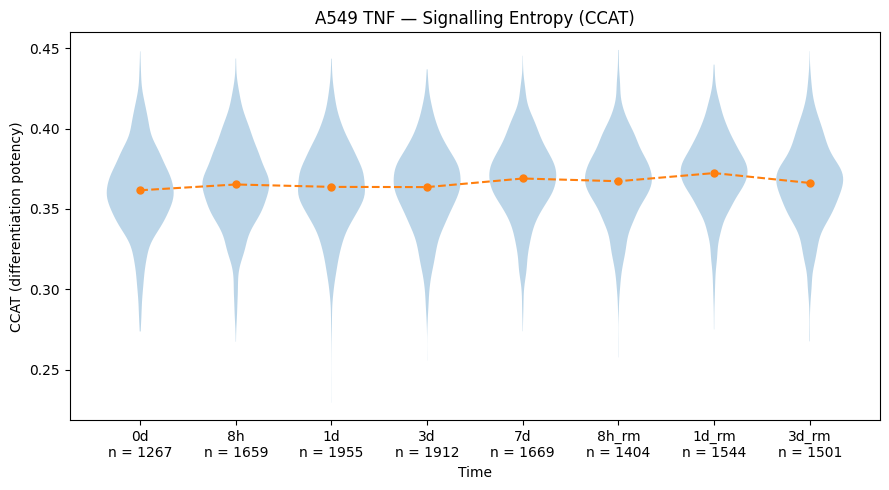

In [206]:
time_order = ["0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm"]

# ------------------------------------------------------------
# CCAT values for each dose
# ------------------------------------------------------------

ccat_groups = [
    adata.obs.loc[
        adata.obs["Time"] == dose,
        "CCAT"
    ].dropna().values
    for dose in time_order
]

# Calculate the mean CCAT score for each time point to summarize the central tendency of the signalling-network connectivity.
ccat_means = [
    np.mean(group)
    for group in ccat_groups
]

# Number of cells
cell_counts = (
    adata.obs["Time"]
    .value_counts()
    .reindex(time_order)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(time_order))

# Simple violin
ax.violinplot(
    ccat_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Mean trajectory
ax.plot(
    positions,
    ccat_means,
    "o--",
    linewidth=1.5,
    markersize=5
)

# X-axis labels
labels = [
    f"{time}\nn = {int(cell_counts.loc[time])}"
    for time in time_order
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.set_xlabel("Time")
ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title("A549 TNF — Signalling Entropy (CCAT)")

plt.tight_layout()
plt.show()

##### <p style="color:coral">Interpretation</p>

For each time point, the violin represents the distribution of CCAT values across individual cells, while the dashed trajectory connects the mean CCAT values.

CCAT is a transcriptome–connectome correlation measure: it quantifies the extent to which the expression profile of a cell is correlated with the connectivity (degree) of genes in the PPI network. Changes in the mean CCAT across time therefore provide an estimate of changes in signalling-network organization associated with differentiation.

The number of cells (\(n\)) is shown for each time point because differences in sample size can affect the apparent stability of the estimated distribution and mean.

### <p style="color:pink">Statistical Test</p>

In [207]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST — CCAT
# ============================================================

tukey_ccat = pairwise_tukeyhsd(
    endog=adata.obs["CCAT"],
    groups=adata.obs["Time"],
    alpha=0.05
)

print(tukey_ccat)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
    0d     1d   0.0021 0.2992 -0.0007  0.0049  False
    0d  1d_rm   0.0107    0.0  0.0078  0.0136   True
    0d     3d    0.002 0.3888 -0.0008  0.0048  False
    0d  3d_rm   0.0046 0.0001  0.0016  0.0075   True
    0d     7d   0.0073    0.0  0.0044  0.0102   True
    0d     8h   0.0036 0.0037  0.0007  0.0065   True
    0d  8h_rm   0.0056    0.0  0.0026  0.0086   True
    1d  1d_rm   0.0086    0.0   0.006  0.0112   True
    1d     3d  -0.0001    1.0 -0.0026  0.0024  False
    1d  3d_rm   0.0025 0.0945 -0.0002  0.0051  False
    1d     7d   0.0052    0.0  0.0026  0.0078   True
    1d     8h   0.0015 0.6429 -0.0011  0.0041  False
    1d  8h_rm   0.0035  0.002  0.0008  0.0062   True
 1d_rm     3d  -0.0087    0.0 -0.0114 -0.0061   True
 1d_rm  3d_rm  -0.0061    0.0  -0.009 -0.0033   True
 1d_rm     7d  -0.0034 0.0044 -0.0061 -0.0006 

##### <p style="color:coral">Tukey's HSD post-hoc test -->

Tukey's Honestly Significant Difference (HSD) test performs all pairwise comparisons between time points after considering the variability within groups.

For two time points \(i\) and \(j\), the test evaluates whether their mean CCAT scores differ:

\[
H_0: \mu_i = \mu_j
\]

\[
H_A: \mu_i \neq \mu_j
\]

The test accounts for the fact that many pairwise comparisons are being performed simultaneously, controlling the **family-wise Type I error rate** at \(\alpha = 0.05\).

The output reports the mean difference, confidence interval, and adjusted significance decision for each pair of time points. A `reject = True` result indicates a statistically significant difference in mean CCAT between those two time points.

In [208]:
# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_ccat_df = pd.DataFrame(
    data=tukey_ccat._results_table.data[1:],
    columns=tukey_ccat._results_table.data[0]
)

tukey_ccat_df["p-adj"] = (
    tukey_ccat_df["p-adj"].astype(float)
)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

ccat_padj = pd.DataFrame(
    np.nan,
    index=time_order,
    columns=time_order
)


for _, row in tukey_ccat_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]

    ccat_padj.loc[group1, group2] = row["p-adj"]
    ccat_padj.loc[group2, group1] = row["p-adj"]


display(ccat_padj)

,0d,8h,1d,3d,7d,8h_rm,1d_rm,3d_rm
0d,NaN,0.0037,0.2992,0.3888,0.0000,0.0000,0.0000,0.0001
8h,0.0037,NaN,0.6429,0.5454,0.0007,0.3622,0.0000,0.9677
1d,0.2992,0.6429,NaN,1.0000,0.0000,0.0020,0.0000,0.0945
3d,0.3888,0.5454,1.0000,NaN,0.0000,0.0012,0.0000,0.0659
7d,0.0000,0.0007,0.0000,0.0000,NaN,0.5926,0.0044,0.0470
8h_rm,0.0000,0.3622,0.0020,0.0012,0.5926,NaN,0.0000,0.9503
1d_rm,0.0000,0.0000,0.0000,0.0000,0.0044,0.0000,NaN,0.0000
3d_rm,0.0001,0.9677,0.0945,0.0659,0.0470,0.9503,0.0000,NaN


##### <p style="color:coral">Pairwise adjusted p-value matrix

Each cell contains the Tukey-adjusted p-value for comparing the mean CCAT scores between two time points:

[
H_0:\mu_i=\mu_j
]

The matrix is symmetric because comparing time point (i) with (j) gives the same p-value as comparing (j) with (i):

[
P_{ij}=P_{ji}
]

The diagonal is left as NaN because a time point is not compared against itself.

This matrix can be used directly to create a CCAT pairwise significance heatmap.

### <p style="color:pink">Tukey test visualisation</p>

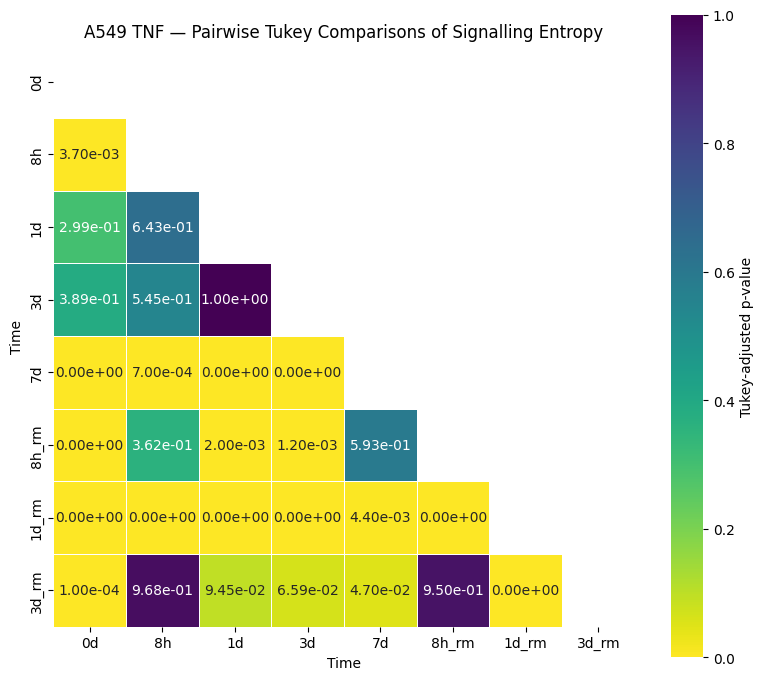

In [209]:
# ============================================================
# CCAT — PAIRWISE TUKEY HEATMAP
# ============================================================

# Mask the upper triangle so each pairwise comparison is displayed only once.
mask = np.triu(
    np.ones_like(ccat_padj, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    ccat_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "A549 TNF — Pairwise Tukey Comparisons of Signalling Entropy"
)

plt.xlabel("Time")
plt.ylabel("Time")

plt.tight_layout()
plt.show()

##### <p style="color:coral">How to interpret the heatmap 

Each cell represents the **Tukey-adjusted p-value** for a pairwise comparison of mean CCAT scores between two time points. The statistical hypothesis for each comparison is: $$ H_0: \mu_i = \mu_j $$ where $\mu_i$ and $\mu_j$ are the mean CCAT scores for time points $i$ and $j$. </br>**Adjusted p-value < 0.05:** statistically significant difference in mean CCAT between the two time points. </br>**Adjusted p-value ≥ 0.05:** no statistically significant difference detected.

/tmp/ipykernel_861501/3225630125.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Time")["CCAT"]
/tmp/ipykernel_861501/3225630125.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Time")["CCAT"]
/tmp/ipykernel_861501/3225630125.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Time")["CCAT"]
/tmp/ipykernel_861501/3225630125.py:25: FutureWarning: The default of observed=False is dep

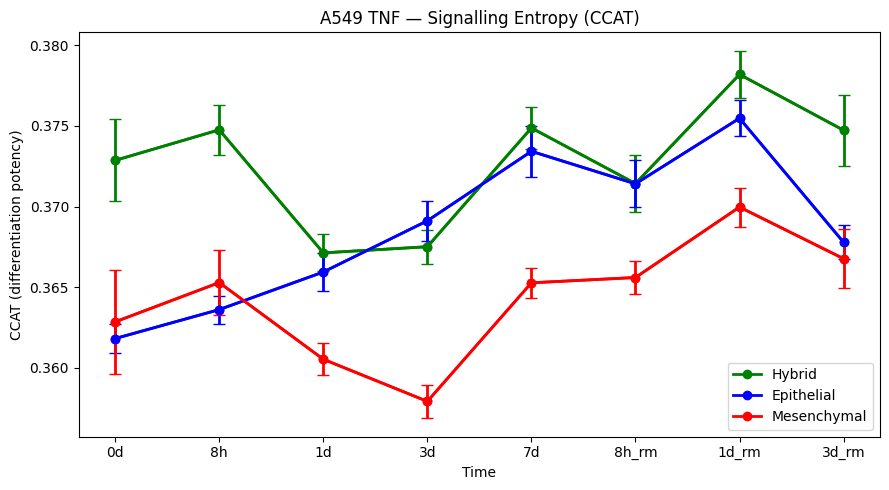

In [210]:
import matplotlib.pyplot as plt
import numpy as np

time_order = ["0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm"]

phenotype_colors = {
    "hybrid": "green",
    "epithelial": "blue",
    "mesenchymal": "red"
}

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(time_order))

for phenotype, color in phenotype_colors.items():

    subset = adata.obs[
        adata.obs["phenotype"] == phenotype
    ]

    # Calculate mean for each time point by phenotype
    means = (
        subset
        .groupby("Time")["CCAT"]
        .mean()
        .reindex(time_order)
    )

    # Calculate standard deviation for each group
    stds = ( 
        subset 
        .groupby("Time")["CCAT"] 
        .std() 
        .reindex(time_order)
    )

    # Calculate number of cells in each phenotype/time-point group
    n = (
        subset
        .groupby("Time")["CCAT"]
        .count()
        .reindex(time_order)
    )

    ax.plot(
        x,
        means.values,
        marker="o",
        linewidth=2,
        color=color,
        label=phenotype.capitalize()
    )

    # Standard error of the mean
    sem = stds / np.sqrt(n)

    ax.errorbar(
        x,
        means.values,
        yerr=sem.values,
        marker="o",
        linewidth=2,
        capsize=4,
        color=color
        # label=phenotype.capitalize()
    )

ax.set_xticks(x)

ax.set_xticklabels([
    f"{time}"
    for time in time_order
])

ax.set_xlabel("Time")
ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title("A549 TNF — Signalling Entropy (CCAT)")

ax.legend()

plt.tight_layout()
plt.show()

### <p style="color:pink">KS and 76GS scores

In [211]:
import sys

repo_root = "/home/csb/Saloni/SCENT/data/EMT_Scoring_KS_76GS"

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from scoring import ks, gs76

##### <p style="color:coral">EMT scoring methods

Two independent EMT scoring methods are imported for comparison:

- **KS score:** a canonical, dataset-independent EMT score based on the Tan et al. EMT gene signatures. More positive values indicate a more **mesenchymal** state, while more negative values indicate a more **epithelial** state.
- **76GS score:** a gene-signature-based EMT score derived from the 76-gene signature. In this implementation, more positive values indicate a more **epithelial** state, while more negative values indicate a more **mesenchymal** state.

These scores provide complementary measures of EMT state that can be compared with the **phenotype classification** and **CCAT/differentiation-potency trajectories** calculated above.

### <p style="color:pink">Verify how expression data is stored in the MAGIC-processed AnnData object.

In [212]:
print(type(adata_magic.X))
print(adata_magic.X.shape)

print("layers:", adata_magic.layers.keys())
print("raw:", adata_magic.raw)

<class 'numpy.ndarray'>
(12911, 13143)
layers: KeysView(Layers with keys: )
raw: None


In [213]:
# Check that the KS EMT gene signatures are being loaded correctly from your scoring package, and then preview the first few genes from each signature.
from scoring import signatures

epi = signatures.get("ks_epithelial", "human")
mes = signatures.get("ks_mesenchymal", "human")

print(epi[:20])
print(mes[:20])

['CDH1', 'AGR2', 'EPCAM', 'KRT19', 'RAB25', 'TACSTD2', 'S100P', 'CEACAM6', 'GALNT3', 'FXYD3', 'SPINT2', 'TMEM30B', 'SCNN1A', 'ST14', 'ESRP1', 'S100A14', 'CLDN7', 'ERBB3', 'RBM47', 'SPINT1']
['VIM', 'ZEB1', 'EMP3', 'SACS', 'AXL', 'LOXL2', 'SPARC', 'FHL1', 'FERMT2', 'TUBA1A', 'TMEM158', 'CALD1', 'LGALS1', 'PMP22', 'MSN', 'GLYR1', 'MAP1B', 'AP1S2', 'GJA1', 'DENND5A']


In [214]:
# Signature coverage check for Tan2014 gene sets 
epi_genes = [g for g in tan_epi if g in adata_magic.var_names]
mes_genes = [g for g in tan_mes if g in adata_magic.var_names]

print("  E genes present:", len(epi_genes), "/", len(tan_epi))
print("  M genes present:", len(mes_genes), "/", len(tan_mes))
print("  Total present:", len(set(epi_genes + mes_genes)))

  E genes present: 133 / 170
  M genes present: 42 / 46
  Total present: 175


In [215]:
# Signature coverage check for epi KS and mes KS gene sets 
epi_check = [g for g in epi if g in adata_magic.var_names]
mes_check = [g for g in mes if g in adata_magic.var_names]

print("Epithelial:", len(epi_check), "/", len(epi))
print("Mesenchymal:", len(mes_check), "/", len(mes))

Epithelial: 133 / 170
Mesenchymal: 43 / 48


In [216]:
# Check the maximum value in the MAGIC-transformed expression matrix.
print(adata_magic.X.max())

6.208720624823753


### <p style="color:pink">Compute KS score

In [217]:
ks.score(adata_magic, species="human")

[KS] human: scored 12911 obs (epi 133/170, mes 43/48) -> obs['KS_score']


AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime', 'KS_score', 'KS_epi_detected', 'KS_mes_detected'
    uns: 'log1p', 'EMT_scoring'

##### <p style="color:coral">KS EMT score</p>
The KS score assigns each cell a continuous score representing its position along the **epithelial–mesenchymal transition (EMT) axis**. </br>The score is based on the relative expression of the predefined epithelial and mesenchymal KS gene signatures. </br>For this implementation: </br>- **Higher KS score** → more mesenchymal state. </br>- **Lower KS score** → more epithelial state. </br>- Intermediate values → intermediate EMT states.

In [218]:
# Copy the KS scores calculated on the MAGIC-processed data into the main AnnData object for downstream analysis.
adata.obs["KS_score"] = adata_magic.obs["KS_score"].values

In [219]:
# Summarize the distribution of KS scores across all cells.
print(adata_magic.obs["KS_score"].describe())

count    12911.000000
mean         0.279427
std          0.052280
min         -0.067844
25%          0.249344
50%          0.286938
75%          0.317013
max          0.415457
Name: KS_score, dtype: float64


In [220]:
# Calculate the mean KS score at each time point.
print(
    adata_magic.obs.groupby("Time")["KS_score"].mean()
)

Time
0d       0.239537
1d       0.275275
1d_rm    0.295672
3d       0.283353
3d_rm    0.275927
7d       0.303343
8h       0.249506
8h_rm    0.308661
Name: KS_score, dtype: float32


/tmp/ipykernel_861501/1846354096.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata_magic.obs.groupby("Time")["KS_score"].mean()


/tmp/ipykernel_861501/2741655702.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Time")["KS_score"]


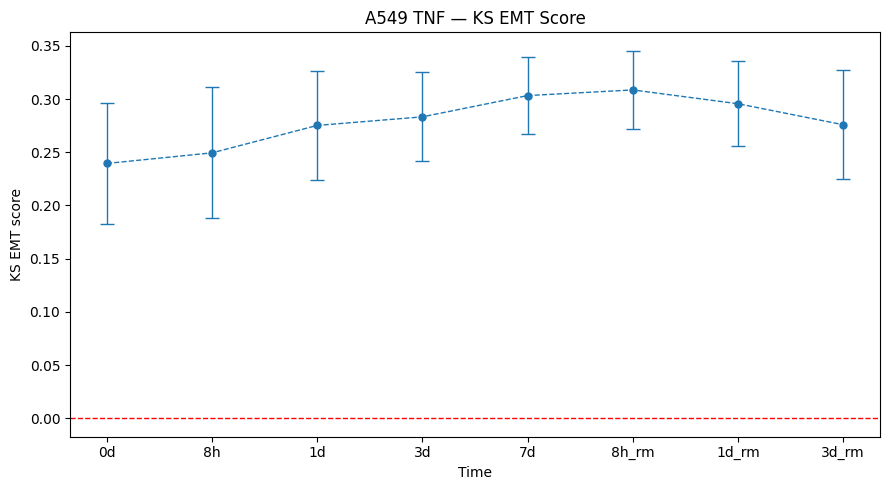

In [221]:
import numpy as np
import matplotlib.pyplot as plt

time_order = ["0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm"]

# ============================================================
# KS SCORE — MEAN ± SD
# ============================================================

# Calculate the mean, standard deviation, and number of cells for the KS score at each time point.
ks_summary = (
    adata_magic.obs
    .groupby("Time")["KS_score"]
    .agg(["mean", "std", "count"])
    .reindex(time_order)
)

x = np.arange(len(time_order))

plt.figure(figsize=(9, 5))

# Plot the mean KS score with ±1 SD error bars.
plt.errorbar(
    x,
    ks_summary["mean"],
    yerr=ks_summary["std"],
    fmt="o--",
    linewidth=1,
    markersize=5,
    capsize=5
)

# Mark zero as a reference point for the KS score.
plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="red"
)

plt.xticks(
    x,
    time_order
)

plt.xlabel("Time")
plt.ylabel("KS EMT score")

plt.title("A549 TNF — KS EMT Score")

plt.tight_layout()
plt.show()

##### <p style="color:coral">KS EMT score trajectory 
The plot shows the **mean KS EMT score** at each time point, with error bars representing **±1 standard deviation (SD)** across cells. </br>The KS score is oriented along the EMT axis such that: </br>- **Higher KS scores** indicate a more mesenchymal state. </br>- **Lower KS scores** indicate a more epithelial state. </br>- Values around zero represent intermediate positions on the EMT axis. </br></br>The SD error bars describe the **cell-to-cell variability** in KS scores within each time point </br>The horizontal line at zero provides a reference for interpreting whether the average population is positioned toward the epithelial or mesenchymal side of the EMT axis.

### <p style="color:pink">Compute 76GS score

In [222]:
from scoring import gs76

gs76.score(
    adata_magic,
    species="human",
    score_name="GS76_score"
)

[GS76] human: 51/76 signature genes present.
[GS76] human: scored 12911 obs -> obs['GS76_score']


AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime', 'KS_score', 'KS_epi_detected', 'KS_mes_detected', 'GS76_score'
    uns: 'log1p', 'EMT_scoring'
    obsm: 'GS76_contributions'

In [223]:
# Copy the 76GS scores calculated on the MAGIC-processed data into the main AnnData object for downstream analysis.
adata.obs["GS76_score"] = adata_magic.obs["GS76_score"].values

In [224]:
print(adata_magic.obs["GS76_score"].describe())

count    1.291100e+04
mean    -6.604068e-18
std      2.003188e-01
min     -4.576261e-01
25%     -1.458215e-01
50%     -6.069944e-03
75%      1.454731e-01
max      6.881200e-01
Name: GS76_score, dtype: float64


/tmp/ipykernel_861501/2266435221.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Time")["GS76_score"]


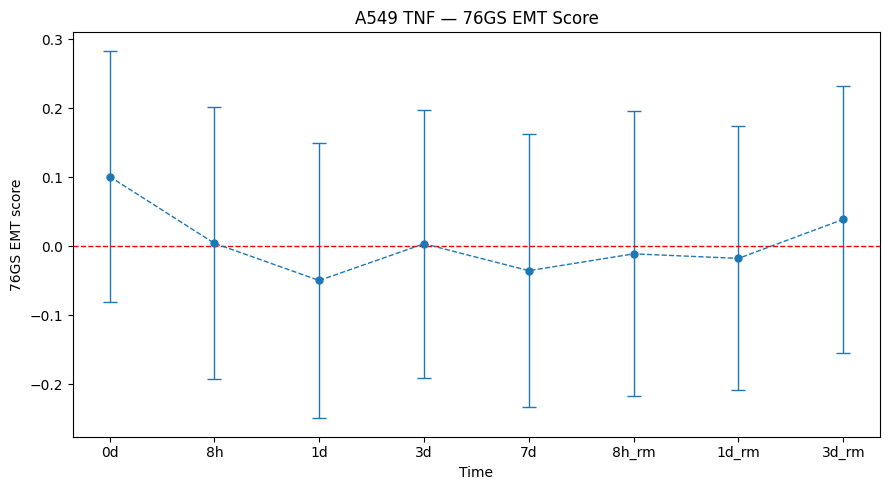

In [225]:
# ============================================================
# 76GS SCORE — MEAN ± SD
# ============================================================

# Calculate the mean, standard deviation, and number of cells for the 76GS score at each time point.
gs76_summary = (
    adata_magic.obs
    .groupby("Time")["GS76_score"]
    .agg(["mean", "std", "count"])
    .reindex(time_order)
)

x = np.arange(len(time_order))

plt.figure(figsize=(9, 5))

# Plot the mean 76GS score with ±1 SD error bars.
plt.errorbar(
    x,
    gs76_summary["mean"],
    yerr=gs76_summary["std"],
    fmt="o--",
    linewidth=1,
    markersize=5,
    capsize=5
)

# Mark zero as a reference point for the EMT score.
plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="red"
)

plt.xticks(
    x,
    time_order
)

plt.xlabel("Time")
plt.ylabel("76GS EMT score")

plt.title("A549 TNF — 76GS EMT Score")

plt.tight_layout()
plt.show()

##### <p style="color:coral">76GS EMT score trajectory
The plot shows the **mean 76GS EMT score** at each time point, with error bars representing **±1 standard deviation (SD)** across cells. </br></br>For this implementation, the 76GS score is oriented such that: </br>- **Higher 76GS scores** indicate a more epithelial state. </br>- **Lower 76GS scores** indicate a more mesenchymal state. </br>- Intermediate values represent intermediate positions along the EMT axis.
</br></br>The horizontal line at zero provides a reference point for interpreting the direction of the EMT trajectory.
</br>**Important:** The 76GS score has the opposite orientation to the KS score used above. Therefore, an increase in KS corresponds to a more mesenchymal state, whereas an increase in 76GS corresponds to a more epithelial state.

Pearson r = -0.6389, p = 0.0000e+00
Spearman rho = -0.6354, p = 0.0000e+00


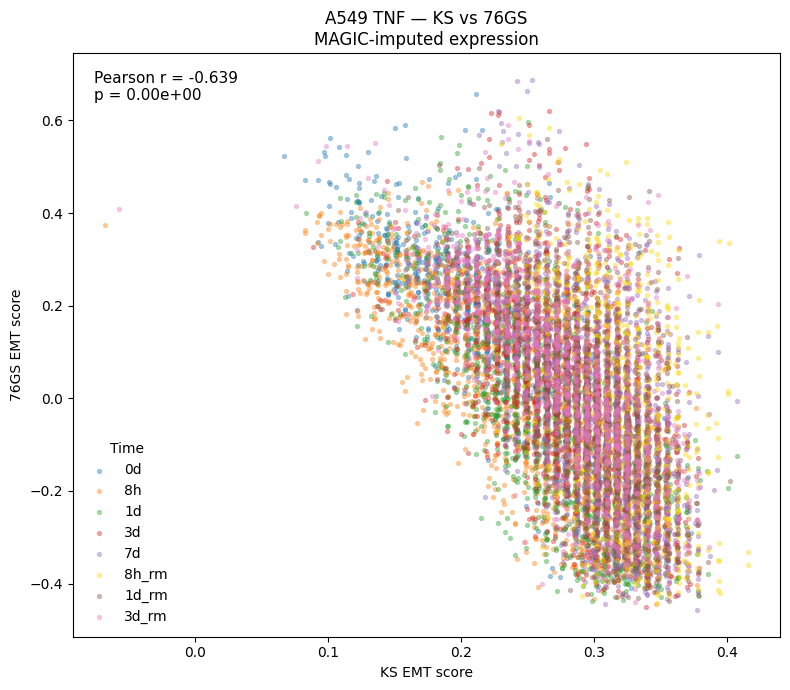

In [226]:
from scipy.stats import pearsonr, spearmanr

# ============================================================
# REMOVE MISSING VALUES
# ============================================================

plot_data = adata_magic.obs[
    ["KS_score", "GS76_score", "Time"]
].dropna()


# ============================================================
# CORRELATIONS
# ============================================================

# Pearson correlation measures the strength of a linear relationship between the KS and 76GS scores.
pearson_r, pearson_p = pearsonr(
    plot_data["KS_score"],
    plot_data["GS76_score"]
)

# Spearman correlation measures the strength of a monotonic relationship using the ranks of the two scores.
spearman_r, spearman_p = spearmanr(
    plot_data["KS_score"],
    plot_data["GS76_score"]
)

print(
    f"Pearson r = {pearson_r:.4f}, "
    f"p = {pearson_p:.4e}"
)

print(
    f"Spearman rho = {spearman_r:.4f}, "
    f"p = {spearman_p:.4e}"
)


# ============================================================
# COLORS FOR TIME POINTS
# ============================================================

time_order = [ "0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm" ]

time_colors = {
    "0d":    "tab:blue",
    "8h":    "tab:orange",
    "1d":    "tab:green",
    "3d":    "tab:red",
    "7d":    "tab:purple",
    "8h_rm": "gold",
    "1d_rm": "tab:brown",
    "3d_rm": "tab:pink"
}


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 7))

for time in time_order:

    subset = plot_data[
        plot_data["Time"].astype(str) == time
    ]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["KS_score"],
        subset["GS76_score"],
        s=8,
        alpha=0.35,
        color=time_colors[time],
        label=time
    )


# ============================================================
# CORRELATION ANNOTATION
# ============================================================

plt.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=plt.gca().transAxes,
    ha="left",
    va="top",
    fontsize=11
)


plt.xlabel("KS EMT score")
plt.ylabel("76GS EMT score")

plt.title("A549 TNF — KS vs 76GS\nMAGIC-imputed expression")

plt.legend(
    title="Time",
    frameon=False
)

plt.tight_layout()
plt.show()

##### <p style="color:coral">KS vs 76GS Correlation

This scatter plot compares the EMT scores assigned to individual cells by the **KS** and **76GS** methods. Each point represents one cell, with color indicating its experimental time point.

Two correlation measures are calculated:

##### Pearson Correlation

Pearson's correlation coefficient measures the strength and direction of a **linear relationship** between the two scores:

$$
r =
\frac{
\sum_i (x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{\sum_i(x_i-\bar{x})^2}
\sqrt{\sum_i(y_i-\bar{y})^2}
}
$$

where $x$ is the KS score and $y$ is the 76GS score.

##### Spearman Correlation

Spearman's $\rho$ measures the strength of a **monotonic relationship** between the two scores using their ranks rather than their raw values. It is therefore less sensitive to non-linear relationships and outliers.

##### Interpreting the Direction

The two scoring methods use **opposite score orientations**:

* **KS:** higher score → more **mesenchymal**
* **76GS:** higher score → more **epithelial**

Therefore, if the two methods agree on the underlying EMT state, we expect a **negative correlation**:

$$
\text{KS} \uparrow
\quad\Longleftrightarrow\quad
\text{76GS} \downarrow
$$

A strong negative correlation would therefore indicate good concordance between the two EMT scoring methods.

The **p-value** tests the null hypothesis that there is **no association** between the two scores. Statistical significance alone does not indicate how strong the agreement is, so the correlation coefficient itself should also be considered.


In [227]:
from itertools import combinations
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# ============================================================
# FUNCTION FOR PAIRWISE WELCH T-TESTS
# ============================================================

def pairwise_welch(
    adata,
    score_column,
    group_column="Time",
    group_order=None
):

    results = []

    for g1, g2 in combinations(group_order, 2):

        x1 = adata.obs.loc[
            adata.obs[group_column].astype(str) == g1,
            score_column
        ].dropna()

        x2 = adata.obs.loc[
            adata.obs[group_column].astype(str) == g2,
            score_column
        ].dropna()

        if len(x1) == 0 or len(x2) == 0:
            continue

        statistic, pvalue = ttest_ind(
            x1,
            x2,
            equal_var=False
        )

        results.append({
            "Group1": g1,
            "Group2": g2,
            "n1": len(x1),
            "n2": len(x2),
            "t_stat": statistic,
            "p_value": pvalue
        })

    results = pd.DataFrame(results)

    # --------------------------------------------------------
    # FDR correction
    # --------------------------------------------------------

    results["p_adj"] = multipletests(
        results["p_value"],
        method="fdr_bh"
    )[1]

    return results

In [228]:
# ============================================================
# KS PAIRWISE COMPARISONS
# ============================================================

ks_pairwise = pairwise_welch(
    adata,
    "KS_score",
    group_order=time_order
)

display(ks_pairwise)

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,0d,8h,1267,1659,-4.546544,5.682878e-06,6.120022e-06
1,0d,1d,1267,1955,-18.208245,1.178068e-69,2.537378e-69
2,0d,3d,1267,1912,-23.631501,5.540533e-110,2.216213e-109
3,0d,7d,1267,1669,-35.077282,5.836756e-211,8.171459e-210
4,0d,8h_rm,1267,1404,-36.965013,1.039150e-231,2.909620e-230
5,0d,1d_rm,1267,1544,-29.771120,5.345617e-164,2.993546e-163
6,0d,3d_rm,1267,1501,-17.621510,1.035322e-65,2.070644e-65
7,8h,1d,1659,1955,-13.576063,7.238319e-41,1.192194e-40
8,8h,3d,1659,1912,-18.955582,1.456289e-75,3.706919e-75
9,8h,7d,1659,1669,-30.779711,2.287824e-178,1.601477e-177


In [229]:
# ============================================================
# 76GS PAIRWISE COMPARISONS
# ============================================================

gs76_pairwise = pairwise_welch(
    adata,
    "GS76_score",
    group_order=time_order
)

display(gs76_pairwise)

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,0d,8h,1267,1659,13.725390,1.504334e-41,7.020226e-41
1,0d,1d,1267,1955,22.058847,9.552080e-100,2.674582e-98
2,0d,3d,1267,1912,14.369706,3.034774e-45,1.699474e-44
3,0d,7d,1267,1669,19.343679,2.156008e-78,3.018412e-77
4,0d,8h_rm,1267,1404,14.887743,3.235970e-48,2.265179e-47
5,0d,1d_rm,1267,1544,16.783506,2.927029e-60,2.731894e-59
6,0d,3d_rm,1267,1501,8.650023,8.628225e-18,2.684337e-17
7,8h,1d,1659,1955,8.143796,5.258881e-16,1.338624e-15
8,8h,3d,1659,1912,0.103186,9.178213e-01,9.178213e-01
9,8h,7d,1659,1669,5.798101,7.333864e-09,1.368988e-08


In [230]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# TIME ORDER
# ============================================================

time_order = [
    "0d",
    "8h",
    "1d",
    "3d",
    "7d",
    "8h_rm",
    "1d_rm",
    "3d_rm"
]


# ============================================================
# FUNCTION FOR PAIRWISE WELCH T-TEST + FDR
# ============================================================

def pairwise_padj(data, score_col, time_order):

    # --------------------------------------------------------
    # Store raw p-values
    # --------------------------------------------------------

    results = []

    for i in range(len(time_order)):

        for j in range(i + 1, len(time_order)):

            t1 = time_order[i]
            t2 = time_order[j]

            group1 = data.loc[
                data["Time"] == t1,
                score_col
            ].dropna()

            group2 = data.loc[
                data["Time"] == t2,
                score_col
            ].dropna()

            # Welch's t-test
            stat, p = ttest_ind(
                group1,
                group2,
                equal_var=False
            )

            results.append({
                "Time1": t1,
                "Time2": t2,
                "p": p
            })


    results = pd.DataFrame(results)


    # --------------------------------------------------------
    # Benjamini-Hochberg FDR correction
    # --------------------------------------------------------

    results["p_adj"] = multipletests(
        results["p"],
        method="fdr_bh"
    )[1]


    # --------------------------------------------------------
    # Create symmetric matrix
    # --------------------------------------------------------

    matrix = pd.DataFrame(
        np.nan,
        index=time_order,
        columns=time_order
    )

    for _, row in results.iterrows():

        matrix.loc[row["Time1"], row["Time2"]] = row["p_adj"]
        matrix.loc[row["Time2"], row["Time1"]] = row["p_adj"]


    return matrix, results


# ============================================================
# KS SCORE — PAIRWISE STATISTICS
# ============================================================

ks_padj, ks_results = pairwise_padj(
    adata.obs,
    "KS_score",
    time_order
)

display(ks_results)


# ============================================================
# 76GS SCORE — PAIRWISE STATISTICS
# ============================================================

gs76_padj, gs76_results = pairwise_padj(
    adata.obs,
    "GS76_score",
    time_order
)

display(gs76_results)

,Time1,Time2,p,p_adj
0,0d,8h,5.682878e-06,6.120022e-06
1,0d,1d,1.178068e-69,2.537378e-69
2,0d,3d,5.540533e-110,2.216213e-109
3,0d,7d,5.836756e-211,8.171459e-210
4,0d,8h_rm,1.039150e-231,2.909620e-230
5,0d,1d_rm,5.345617e-164,2.993546e-163
6,0d,3d_rm,1.035322e-65,2.070644e-65
7,8h,1d,7.238319e-41,1.192194e-40
8,8h,3d,1.456289e-75,3.706919e-75
9,8h,7d,2.287824e-178,1.601477e-177


,Time1,Time2,p,p_adj
0,0d,8h,1.504334e-41,7.020226e-41
1,0d,1d,9.552080e-100,2.674582e-98
2,0d,3d,3.034774e-45,1.699474e-44
3,0d,7d,2.156008e-78,3.018412e-77
4,0d,8h_rm,3.235970e-48,2.265179e-47
5,0d,1d_rm,2.927029e-60,2.731894e-59
6,0d,3d_rm,8.628225e-18,2.684337e-17
7,8h,1d,5.258881e-16,1.338624e-15
8,8h,3d,9.178213e-01,9.178213e-01
9,8h,7d,7.333864e-09,1.368988e-08


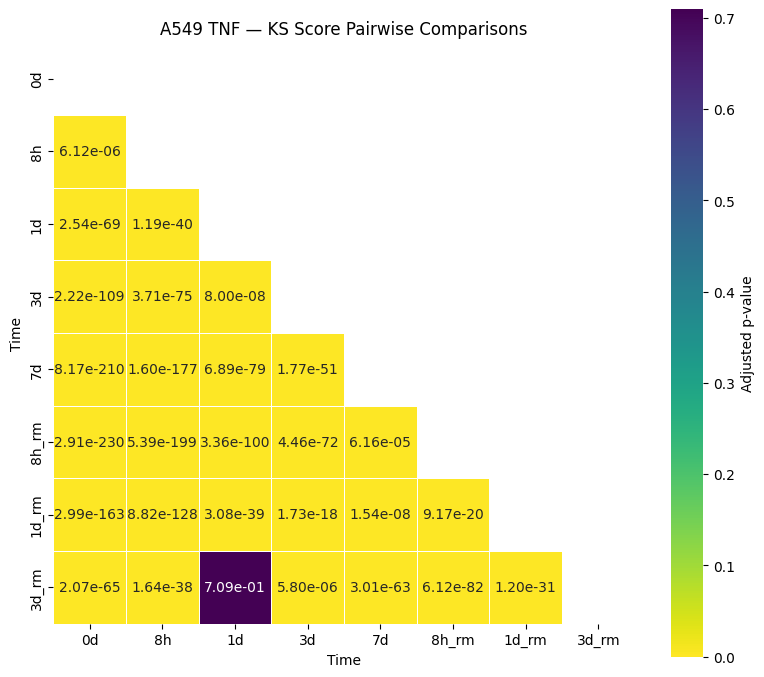

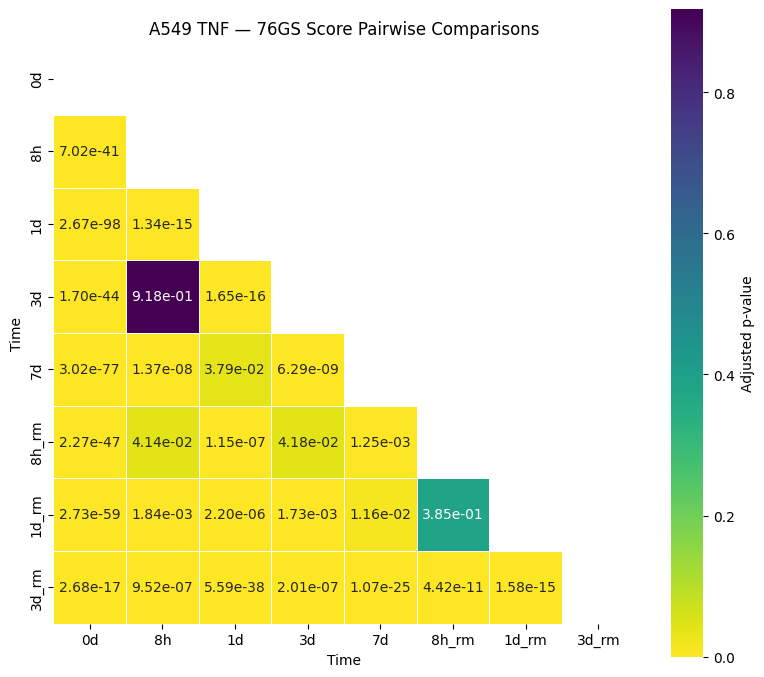

In [231]:
# ============================================================
# KS HEATMAP — LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(ks_padj, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    ks_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Adjusted p-value"}
)

plt.title("A549 TNF — KS Score Pairwise Comparisons")
plt.xlabel("Time")
plt.ylabel("Time")

plt.tight_layout()
plt.show()


# ============================================================
# 76GS HEATMAP — LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(gs76_padj, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    gs76_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Adjusted p-value"}
)

plt.title("A549 TNF — 76GS Score Pairwise Comparisons")
plt.xlabel("Time")
plt.ylabel("Time")

plt.tight_layout()
plt.show()

### <p style="color:pink">Pairwise Welch t-test and FDR Correction

Pairwise comparisons are performed between all experimental time points for both the **KS** and **76GS** EMT scores.

##### <p style="color:coral">Welch's t-test

For each pair of time points, a **two-sided Welch's independent-samples t-test** is used to determine whether the mean EMT scores differ between the two groups.

Unlike the standard Student's t-test, Welch's t-test does **not assume equal variances** between groups, making it more appropriate when the variability or number of cells differs between time points.

The test statistic is:

$$
t =
\frac{\bar{x}_1-\bar{x}_2}
{\sqrt{
\frac{s_1^2}{n_1}
+
\frac{s_2^2}{n_2}
}}
$$

where:

* $\bar{x}_1,\bar{x}_2$ are the mean scores of the two time points
* $s_1^2,s_2^2$ are their sample variances
* $n_1,n_2$ are the numbers of cells in each group

The null hypothesis is:

$$
H_0:\mu_1=\mu_2
$$

and the alternative hypothesis is:

$$
H_A:\mu_1\neq\mu_2
$$

A small p-value indicates evidence that the mean EMT scores differ between the two time points.

##### <p style="color:coral">Benjamini–Hochberg FDR Correction

Because every pair of time points is tested, many statistical tests are performed simultaneously. To account for these multiple comparisons, the raw p-values are adjusted using the **Benjamini–Hochberg (BH) procedure**.

The BH procedure controls the **false discovery rate (FDR)**, i.e. the expected proportion of false positives among the comparisons identified as significant.

The adjusted p-values are therefore used for determining statistical significance rather than the raw p-values.

##### <p style="color:coral">Heatmap Interpretation

Each cell in the heatmap represents the **Benjamini–Hochberg adjusted p-value** for a pairwise comparison between two time points.

* **Adjusted p-value < 0.05:** statistically significant difference in mean EMT score.
* **Adjusted p-value ≥ 0.05:** no statistically significant difference detected.
* The **diagonal is `NaN`** because a time point is not compared with itself.
* Only the **lower triangle** is shown because the pairwise comparison matrix is symmetric.

The same analysis is performed independently for the **KS** and **76GS** scores.

##### <p style="color:coral">Important interpretation point

Statistical significance indicates that the **mean scores differ**, but it does not indicate the **direction** or biological magnitude of the difference.

For interpretation of EMT direction:

* **KS:** higher score → more **mesenchymal**
* **76GS:** higher score → more **epithelial**

Therefore, the pairwise p-value heatmaps should be interpreted together with the corresponding **mean ± SD trajectory plots** to determine how the EMT state changes over time.

> **Note:** Because single-cell datasets contain many individual cells, very large sample sizes can produce statistically significant p-values even for relatively small differences. The magnitude and biological interpretation of the score changes should therefore be considered alongside statistical significance.


### <p style="color:pink">Signaling Entropy vs ID plot

In [232]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

In [233]:
import pandas as pd
import numpy as np

# Load the previously calculated ID scores for the A549 EGF dataset.
id_df = pd.read_excel("/home/csb/Saloni/SCENT/data/ID/A549_TNF_ID_local.xlsx")

print(id_df.head())
print(id_df.columns)

              Unnamed: 0        ID
0  Mix1_AAACCTGTCATGCTCC  0.264885
1  Mix1_AAACGGGAGTGTCCCG  0.437658
2  Mix1_AAACGGGCATAGACTC  0.287204
3  Mix1_AAAGCAATCGGTGTCG  0.385720
4  Mix1_AAAGTAGCACAGACTT  0.395935
Index(['Unnamed: 0', 'ID'], dtype='object')


In [234]:
print(adata)

AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'KS_score', 'GS76_score'


In [235]:
# Use the first column as the cell/group identifier so that ID scores can be aligned with the corresponding observations.
id_df = id_df.set_index(id_df.columns[0])

# Ensure identifiers are stored consistently as strings for matching.
id_df.index = id_df.index.astype(str)

In [236]:
print(id_df.head())

                             ID
Unnamed: 0                     
Mix1_AAACCTGTCATGCTCC  0.264885
Mix1_AAACGGGAGTGTCCCG  0.437658
Mix1_AAACGGGCATAGACTC  0.287204
Mix1_AAAGCAATCGGTGTCG  0.385720
Mix1_AAAGTAGCACAGACTT  0.395935


In [237]:
# Add ID scores to adata
adata.obs["ID"] = id_df["ID"].reindex(adata.obs_names)

In [238]:
print(adata)

AnnData object with n_obs × n_vars = 12911 × 13143
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'KS_score', 'GS76_score', 'ID'


In [239]:
print(adata.obs[["ID", "Time"]].head())

print("Cells in adata:", adata.n_obs)
print("Cells with ID:", adata.obs["ID"].notna().sum())
print("Missing ID:", adata.obs["ID"].isna().sum())

                             ID   Time
Mix1_AAACCTGTCATGCTCC  0.264885  1d_rm
Mix1_AAACGGGAGTGTCCCG  0.437658  8h_rm
Mix1_AAACGGGCATAGACTC  0.287204     7d
Mix1_AAAGCAATCGGTGTCG  0.385720  8h_rm
Mix1_AAAGTAGCACAGACTT  0.395935     0d
Cells in adata: 12911
Cells with ID: 12911
Missing ID: 0


In [240]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

plot_data = adata.obs[
    ["ID", "CCAT", "Time"]
].dropna()

# ============================================================
# CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["ID"],
    plot_data["CCAT"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["ID"],
    plot_data["CCAT"]
)

print(f"Pearson r = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4e}")

Pearson r = 0.2777, p = 3.1118e-227
Spearman rho = 0.2682, p = 1.5316e-211


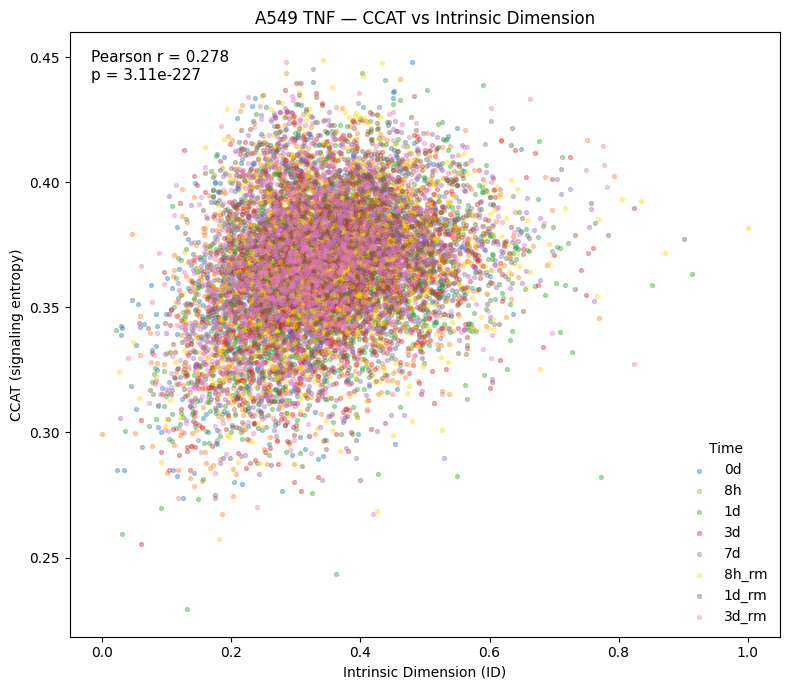

In [241]:
# ============================================================
# COLORS
# ============================================================

time_order = ["0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm"]

time_colors = {
    "0d":    "tab:blue",
    "8h":    "tab:orange",
    "1d":    "tab:green",
    "3d":    "tab:red",
    "7d":    "tab:purple",
    "8h_rm": "gold",
    "1d_rm": "tab:brown",
    "3d_rm": "tab:pink"
}

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 7))

for time in time_order:

    subset = plot_data[
        plot_data["Time"].astype(str) == time
    ]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["ID"],
        subset["CCAT"],
        s=8,
        alpha=0.35,
        color=time_colors[time],
        label=time
    )

# ============================================================
# CORRELATION ANNOTATION
# ============================================================

plt.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=plt.gca().transAxes,
    ha="left",
    va="top",
    fontsize=11
)

plt.xlabel("Intrinsic Dimension (ID)")
plt.ylabel("CCAT (signaling entropy)")

plt.title("A549 TNF — CCAT vs Intrinsic Dimension")

plt.legend(
    title="Time",
    frameon=False
)

plt.tight_layout()
plt.show()

### <p style="color:pink">CCAT vs Intrinsic Dimension

This analysis evaluates the relationship between **Intrinsic Dimension (ID)** and **CCAT (cellular connectome association to transcriptome)** across individual cells.

##### <p style="color:coral">Correlation Analysis

Two complementary correlation measures are calculated.

##### <p style="color:coral">Pearson Correlation

Pearson's correlation coefficient measures the strength and direction of the **linear relationship** between ID and CCAT:

$$
r =
\frac{
\sum_i (ID_i-\overline{ID})(CCAT_i-\overline{CCAT})
}{
\sqrt{\sum_i(ID_i-\overline{ID})^2}
\sqrt{\sum_i(CCAT_i-\overline{CCAT})^2}
}
$$

where $ID_i$ and $CCAT_i$ are the scores for cell $i$.

The value of $r$ ranges from $-1$ to $+1$:

* $r > 0$ → positive linear relationship
* $r < 0$ → negative linear relationship
* $r \approx 0$ → little or no linear relationship

##### <p style="color:coral">Spearman Correlation

Spearman's $\rho$ measures the strength of a **monotonic relationship** between ID and CCAT using the ranks of the observations rather than their raw values.

This is useful when the relationship is not strictly linear or when the data contain outliers.

##### <p style="color:coral">Interpretation

The correlation analysis asks whether cells with different levels of **transcriptomic complexity (ID)** also show systematic differences in their **network-based differentiation potency (CCAT)**.

A **positive correlation** would indicate that higher ID tends to be associated with higher CCAT.

A **negative correlation** would indicate that higher ID tends to be associated with lower CCAT.

The **p-value** tests the null hypothesis that there is no association between ID and CCAT:

$$
H_0: \rho = 0
$$

A statistically significant p-value indicates evidence of an association, while the magnitude and direction of the correlation coefficient indicate the **strength and direction** of that relationship.

> **Important:** Statistical significance does not by itself indicate biological importance. The correlation coefficient should be interpreted together with the scatter plot and the overall trajectories of ID and CCAT across time.


Epithelial genes: 133
Mesenchymal genes: 43
Pearson r = 0.4257, p = 0.0000e+00
Spearman rho = 0.4539, p = 0.0000e+00


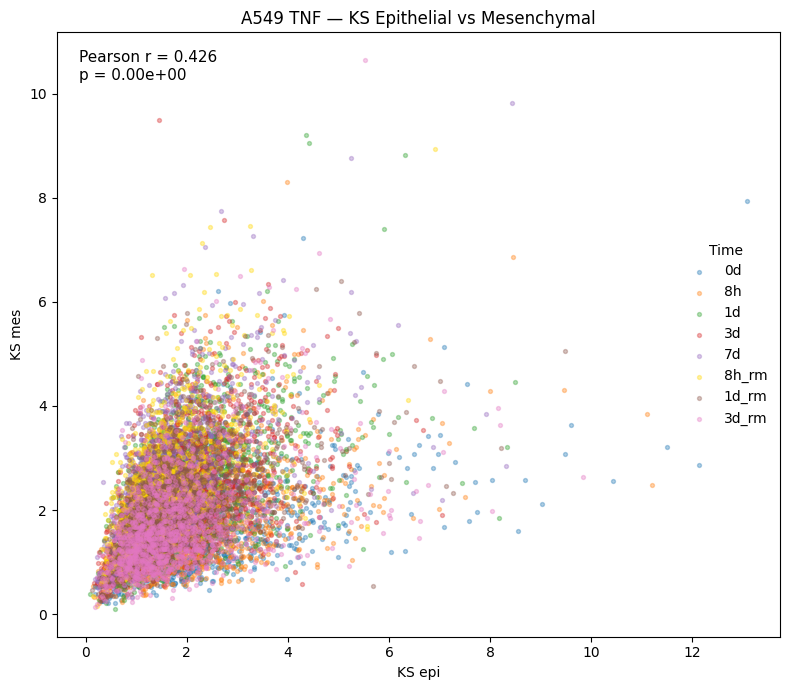

In [243]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

time_order = ["0d", "8h", "1d", "3d", "7d", "8h_rm", "1d_rm", "3d_rm"]

time_colors = {
    "0d":    "tab:blue",
    "8h":    "tab:orange",
    "1d":    "tab:green",
    "3d":    "tab:red",
    "7d":    "tab:purple",
    "8h_rm": "gold",
    "1d_rm": "tab:brown",
    "3d_rm": "tab:pink"
}

# ============================================================
# GET THE SAME KS SIGNATURES USED BY ks.score()
# ============================================================

epi_genes = signatures.get("ks_epithelial", "human")
mes_genes = signatures.get("ks_mesenchymal", "human")

epi_genes = [g for g in epi_genes if g in adata.var_names]
mes_genes = [g for g in mes_genes if g in adata.var_names]

print("Epithelial genes:", len(epi_genes))
print("Mesenchymal genes:", len(mes_genes))


# ============================================================
# EXTRACT EXPRESSION
# ============================================================

epi_idx = [adata.var_names.get_loc(g) for g in epi_genes]
mes_idx = [adata.var_names.get_loc(g) for g in mes_genes]

X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X)


# ============================================================
# PER-CELL SIGNATURE SCORES
# ============================================================

KS_epi = X[:, epi_idx].mean(axis=1)
KS_mes = X[:, mes_idx].mean(axis=1)

adata.obs["KS_epi"] = KS_epi
adata.obs["KS_mes"] = KS_mes


# ============================================================
# REMOVE MISSING / INVALID VALUES
# ============================================================

plot_data = adata.obs[
    ["KS_epi", "KS_mes"]
].dropna()


# ============================================================
# CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["KS_epi"],
    plot_data["KS_mes"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["KS_epi"],
    plot_data["KS_mes"]
)

print(f"Pearson r = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4e}")


# ============================================================
# SCATTER PLOT
# ============================================================

plt.figure(figsize=(8, 7))

for time in time_order:

    subset = plot_data[
        adata.obs.loc[plot_data.index, "Time"].astype(str) == time
    ]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["KS_epi"],
        subset["KS_mes"],
        s=8,
        alpha=0.35,
        color=time_colors[time],
        label=time
    )


plt.xlabel("KS epi")
plt.ylabel("KS mes")

plt.title(
    "A549 TNF — KS Epithelial vs Mesenchymal"
)

plt.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=plt.gca().transAxes,
    ha="left",
    va="top",
    fontsize=11
)

plt.legend(
    title="Time",
    frameon=False
)

plt.tight_layout()
plt.show()

### <p style="color:pink">KS Epithelial vs Mesenchymal Signature Correlation

This analysis evaluates the relationship between the **epithelial** and **mesenchymal** transcriptional programs used by the KS EMT scoring method.

For each cell, two independent signature scores are calculated:

$$
KS_{\mathrm{epi},c}
=
\frac{1}{N_E}
\sum_{g \in E} X_{cg}
$$

$$
KS_{\mathrm{mes},c}
=
\frac{1}{N_M}
\sum_{g \in M} X_{cg}
$$

where:

* $X_{cg}$ is the expression of gene $g$ in cell $c$
* $E$ is the epithelial gene signature
* $M$ is the mesenchymal gene signature
* $N_E$ and $N_M$ are the numbers of signature genes present in the dataset

Thus, each cell receives an **epithelial activity score** and a **mesenchymal activity score** based on the mean expression of the corresponding signature genes.

##### <p style="color:coral">Correlation Analysis

The relationship between the two scores is evaluated using both **Pearson correlation** and **Spearman correlation**.

Pearson correlation measures the strength of the **linear relationship**, whereas Spearman correlation measures the strength of the **monotonic relationship** based on ranks.

##### <p style="color:coral">Interpretation

Because epithelial and mesenchymal programs generally represent opposing transcriptional states, we expect their activities to show a **negative relationship**:

$$
KS_{\mathrm{epi}} \uparrow
\quad\Longleftrightarrow\quad
KS_{\mathrm{mes}} \downarrow
$$

Therefore:

* **Strong negative correlation:** epithelial and mesenchymal programs tend to be mutually exclusive across cells.
* **Weak or near-zero correlation:** the two programs are not strongly coupled.
* **Positive correlation:** cells with high epithelial activity also tend to have high mesenchymal activity, which may indicate **co-expression of both programs** and potentially a hybrid EMT state.

The scatter plot shows this relationship at the **single-cell level**, with colors representing the experimental time points.

> **Note:** These are the underlying epithelial and mesenchymal signature activities, not the final KS EMT score itself. The analysis therefore helps visualize how the two component programs behave independently and whether they tend to oppose or co-exist across cells.
